# PF8 02smogdata: the June 2026 smog episode in numbers

The episode: Santiago had preemergencia (the second of three warning levels) declared on 13, 14 and 15 June 2026, an alert on the 16th, and another preemergencia on the 17th. This notebook gathers the data that will drive the smog in the 3D scene:

1. **PM2.5 at the ground** from Chile's SINCA monitoring network, through the OpenAQ archive on AWS (public, no account). SINCA's own site refuses visitors from outside Chile.
2. **The lid**: the boundary layer height from the ERA5 reanalysis, hour by hour, plus 10 m wind and 2 m temperature, through Open-Meteo's historical weather API (no account for non-commercial use).

**Important:** what OpenAQ holds for these stations is SINCA's **24-hour rolling average** of PM2.5 (the measure used to declare episodes), not raw hourly values. Section 3 checks this. So the concentration in the scene changes slowly (day to day), and the hourly rhythm comes from the lid height.

Outputs: `data/pm25_stations.csv` (one row per station and hour), `data/era5_hourly.csv` (one row per grid point and hour), and two charts.

## 0. Settings

In [1]:
from pathlib import Path
import time
import gzip
import io
import json
import urllib.request
import urllib.parse
import numpy as np
import pandas as pd

DATA_DIR = Path("data")
OPENAQ_DIR = DATA_DIR / "openaq"
START_LOCAL = "2026-06-11"  # <- first day (Santiago local time); one day of margin before the episode
END_LOCAL = "2026-06-19"  # <- last day (Santiago local time); one day of margin after
TIMEZONE = "America/Santiago"

# OpenAQ location ids of SINCA stations in the Santiago basin, found on explore.openaq.org (21 Nov 2026).
STATION_IDS = [332, 2268, 299, 967, 846, 725, 326680, 25, 844, 8788, 852, 849, 45, 54, 1330]  # <- stations to try
OPENAQ_URL = "https://openaq-data-archive.s3.amazonaws.com/records/csv.gz/locationid={id}/year={y}/month={m:02d}/location-{id}-{ymd}.csv.gz"

# ERA5 grid points across the basin (ERA5 cells are about 0.25 degrees, roughly 25 to 30 km here).
ERA5_LATS = [-33.30, -33.45, -33.60]  # <- grid point latitudes
ERA5_LONS = [-70.85, -70.65, -70.45]  # <- grid point longitudes
ERA5_VARS = ["boundary_layer_height", "wind_speed_10m", "wind_direction_10m", "temperature_2m"]
OPENMETEO_URL = "https://archive-api.open-meteo.com/v1/archive"

# Days declared by the authorities (news reports, June 2026), for shading the charts.
PREEMERGENCIA_DAYS = ["2026-06-13", "2026-06-14", "2026-06-15", "2026-06-17"]  # <- preemergencia
ALERTA_DAYS = ["2026-06-16"]  # <- alerta

OPENAQ_DIR.mkdir(parents=True, exist_ok=True)
USER_AGENT = {"User-Agent": "PF8 portfolio notebook (likrentai)"}

## 1. Download the station files (once)

One gzipped CSV per station per day, cached in `data/openaq`. A missing file just means that station has no data that day.

In [2]:
days = pd.date_range(START_LOCAL, END_LOCAL, freq="D")
t0 = time.time()
fetched = 0
missing = 0
for sid in STATION_IDS:
    for d in days:
        ymd = d.strftime("%Y%m%d")
        path = OPENAQ_DIR / f"location-{sid}-{ymd}.csv.gz"
        if path.exists():
            continue
        url = OPENAQ_URL.format(id=sid, y=d.year, m=d.month, ymd=ymd)
        try:
            with urllib.request.urlopen(urllib.request.Request(url, headers=USER_AGENT)) as r:
                path.write_bytes(r.read())
            fetched += 1
        except urllib.error.HTTPError as e:
            missing += 1
print(f"Downloaded {fetched} files, {missing} not in the archive, in {time.time() - t0:.0f} s")

Downloaded 81 files, 54 not in the archive, in 83 s


## 2. Read PM2.5

In [3]:
frames = []
for path in sorted(OPENAQ_DIR.glob("location-*.csv.gz")):
    df = pd.read_csv(path)
    frames.append(df[df["parameter"] == "pm25"])
raw = pd.concat(frames, ignore_index=True)
raw["time_utc"] = pd.to_datetime(raw["datetime"], utc=True)
raw["time_local"] = raw["time_utc"].dt.tz_convert(TIMEZONE)
raw = raw[(raw["time_local"] >= pd.Timestamp(START_LOCAL, tz=TIMEZONE)) & (raw["time_local"] < pd.Timestamp(END_LOCAL, tz=TIMEZONE) + pd.Timedelta(days=1))]
raw["station"] = raw["location"].str.replace(r"-\d+$", "", regex=True).str.replace(" (Acreditada)", "", regex=False).str.strip()

stations = raw.groupby("location_id").agg(station=("station", "first"), lat=("lat", "first"), lon=("lon", "first"), hours=("value", "size"), mean=("value", "mean"), max=("value", "max")).sort_values("lon")
print(stations.round(4).to_string())

                      station      lat      lon  hours     mean    max
location_id                                                           
54                  Talagante -33.6738 -70.9531    215  60.1628   87.0
967                  Pudahuel -33.4378 -70.7502    215  73.4093  132.0
846               Cerro Navia -33.4331 -70.7321    215  75.6512  132.0
2268                Quilicura -33.3496 -70.7238    215  58.2744   85.0
849                 El Bosque -33.5471 -70.6662    215  66.0558   92.0
25           Parque O'Higgins -33.4641 -70.6608    215  60.1767  100.0
45                Puente Alto -33.5914 -70.5948    215  46.1442   69.0
852                La Florida -33.5166 -70.5881    215  52.6000   78.0
1330               Las Condes -33.3768 -70.5233    215  28.5767   50.0


## 3. Check: rolling average or raw hourly?

Raw hourly PM2.5 typically jumps by 5 to 20 µg/m³ from one hour to the next in a Santiago winter. A 24-hour rolling average moves by only a few. The mean hour-to-hour step tells which one OpenAQ holds.

In [4]:
raw = raw.sort_values(["location_id", "time_utc"])
raw["step"] = raw.groupby("location_id")["value"].diff().abs()
steps = raw.groupby("station")["step"].mean().round(2).sort_values()
print(steps.to_string())
print()
print(f"Median of the mean hourly steps: {steps.median():.2f} ug/m3 per hour")

station
Las Condes          0.50
La Florida          0.64
Puente Alto         0.70
Quilicura           0.86
Talagante           0.86
El Bosque           0.93
Parque O'Higgins    0.98
Cerro Navia         1.15
Pudahuel            1.15

Median of the mean hourly steps: 0.86 ug/m3 per hour


## 4. ERA5 lid height, wind and temperature

In [5]:
lat_list = []
lon_list = []
for la in ERA5_LATS:
    for lo in ERA5_LONS:
        lat_list.append(str(la))
        lon_list.append(str(lo))
end_utc = (pd.Timestamp(END_LOCAL) + pd.Timedelta(days=1)).strftime("%Y-%m-%d")
params = {"latitude": ",".join(lat_list), "longitude": ",".join(lon_list), "start_date": START_LOCAL, "end_date": end_utc, "hourly": ",".join(ERA5_VARS), "models": "era5", "timezone": "GMT"}
url = OPENMETEO_URL + "?" + urllib.parse.urlencode(params)
cache = DATA_DIR / "era5_openmeteo.json"
if not cache.exists():
    with urllib.request.urlopen(urllib.request.Request(url, headers=USER_AGENT)) as r:
        cache.write_bytes(r.read())
answer = json.loads(cache.read_text())
if isinstance(answer, dict):
    answer = [answer]

rows = []
for i, point in enumerate(answer):
    h = pd.DataFrame(point["hourly"])
    h["time_utc"] = pd.to_datetime(h["time"], utc=True)
    h["point"] = i
    h["lat_req"] = float(lat_list[i])
    h["lon_req"] = float(lon_list[i])
    h["lat_grid"] = point["latitude"]
    h["lon_grid"] = point["longitude"]
    h["grid_elev"] = point.get("elevation")
    rows.append(h.drop(columns=["time"]))
era5 = pd.concat(rows, ignore_index=True)
era5["time_local"] = era5["time_utc"].dt.tz_convert(TIMEZONE)
era5 = era5[(era5["time_local"] >= pd.Timestamp(START_LOCAL, tz=TIMEZONE)) & (era5["time_local"] < pd.Timestamp(END_LOCAL, tz=TIMEZONE) + pd.Timedelta(days=1))]
print(era5.groupby("point")[["lat_grid", "lon_grid", "grid_elev"]].first().to_string())
print()
print(era5.groupby("point")["boundary_layer_height"].describe()[["min", "50%", "max"]].round(0).to_string())

       lat_grid  lon_grid  grid_elev
point                               
0        -33.25    -70.75      486.0
1        -33.25    -70.75      546.0
2        -33.25    -70.50     1343.0
3        -33.50    -70.75      469.0
4        -33.50    -70.75      554.0
5        -33.50    -70.50     2001.0
6        -33.50    -70.75      409.0
7        -33.50    -70.75      617.0
8        -33.50    -70.50     1113.0

        min   50%    max
point                   
0      10.0  25.0  815.0
1      10.0  25.0  815.0
2      15.0  20.0  600.0
3      10.0  30.0  620.0
4      10.0  30.0  620.0
5      15.0  20.0  460.0
6      10.0  30.0  620.0
7      10.0  30.0  620.0
8      15.0  20.0  460.0


## 5. Charts: PM2.5 by station, and the lid

Shaded days: preemergencia (darker) and alerta (lighter) as declared by the authorities. Station lines are the 24-hour rolling average. The lid chart shows every ERA5 grid point; the thick line is the point nearest the city centre.

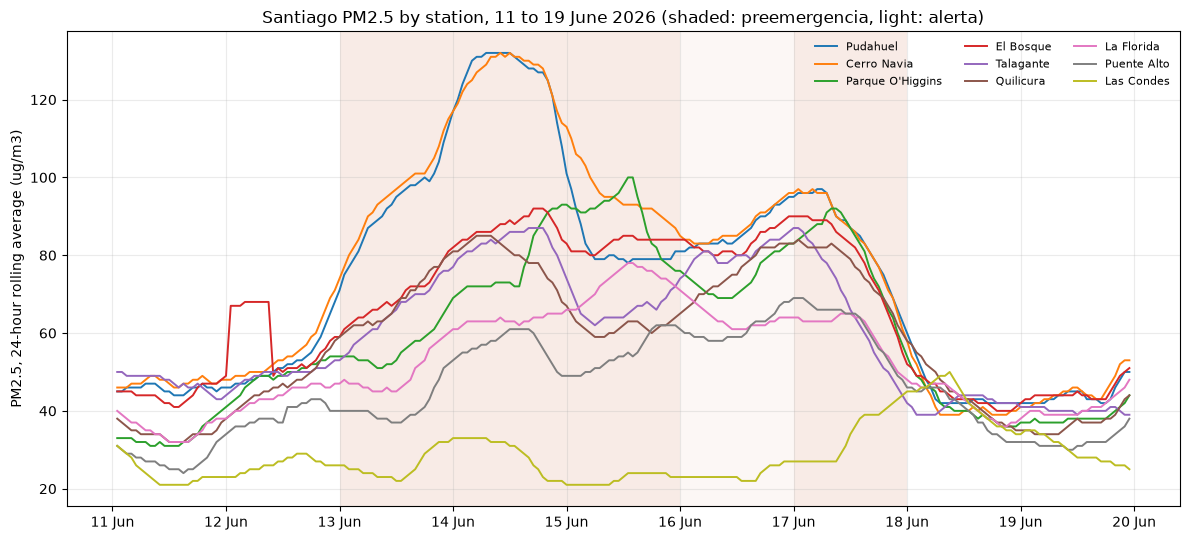

In [6]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

def shade_days(ax):
    for d in PREEMERGENCIA_DAYS:
        start = pd.Timestamp(d, tz=TIMEZONE)
        ax.axvspan(start, start + pd.Timedelta(days=1), color="#c2410c", alpha=0.10, lw=0)
    for d in ALERTA_DAYS:
        start = pd.Timestamp(d, tz=TIMEZONE)
        ax.axvspan(start, start + pd.Timedelta(days=1), color="#c2410c", alpha=0.04, lw=0)

fig, ax = plt.subplots(figsize=(12, 5.5))
shade_days(ax)
order = stations.sort_values("max", ascending=False).index
for sid in order:
    s = raw[raw["location_id"] == sid]
    ax.plot(s["time_local"], s["value"], lw=1.4, label=stations.loc[sid, "station"])
ax.set_ylabel("PM2.5, 24-hour rolling average (ug/m3)")
ax.set_title("Santiago PM2.5 by station, 11 to 19 June 2026 (shaded: preemergencia, light: alerta)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b", tz=TIMEZONE))
ax.legend(fontsize=8, ncol=3, frameon=False)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(DATA_DIR / "chart_pm25.png", dpi=130)
plt.show()

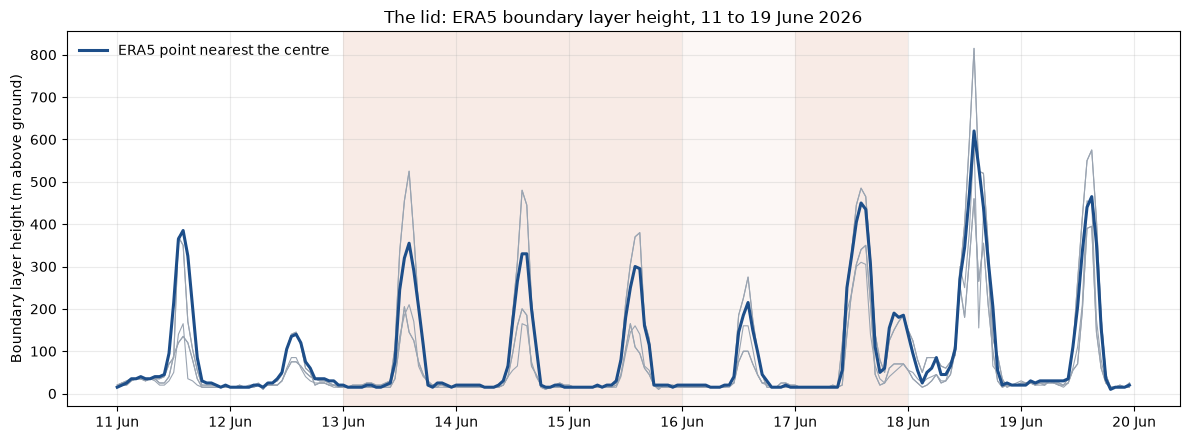

                            min    max
time_local                            
2026-06-11 00:00:00-04:00  15.0  385.0
2026-06-12 00:00:00-04:00  15.0  140.0
2026-06-13 00:00:00-04:00  15.0  355.0
2026-06-14 00:00:00-04:00  15.0  330.0
2026-06-15 00:00:00-04:00  15.0  300.0
2026-06-16 00:00:00-04:00  15.0  215.0
2026-06-17 00:00:00-04:00  15.0  450.0
2026-06-18 00:00:00-04:00  20.0  620.0
2026-06-19 00:00:00-04:00  10.0  465.0


In [7]:
centre = era5.groupby("point")[["lat_req", "lon_req"]].first()
centre_point = ((centre["lat_req"] + 33.45) ** 2 + (centre["lon_req"] + 70.65) ** 2).idxmin()

fig, ax = plt.subplots(figsize=(12, 4.5))
shade_days(ax)
for p, g in era5.groupby("point"):
    if p == centre_point:
        continue
    ax.plot(g["time_local"], g["boundary_layer_height"], lw=0.8, color="#9aa4b1")
g = era5[era5["point"] == centre_point]
ax.plot(g["time_local"], g["boundary_layer_height"], lw=2.2, color="#1d4e89", label="ERA5 point nearest the centre")
ax.set_ylabel("Boundary layer height (m above ground)")
ax.set_title("The lid: ERA5 boundary layer height, 11 to 19 June 2026")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b", tz=TIMEZONE))
ax.legend(frameon=False)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(DATA_DIR / "chart_lid.png", dpi=130)
plt.show()

daily = g.set_index("time_local")["boundary_layer_height"].resample("D").agg(["min", "max"]).round(0)
print(daily.to_string())

## 6. Save

In [8]:
pm = raw[["location_id", "station", "lat", "lon", "time_utc", "time_local", "value"]].rename(columns={"value": "pm25_24h"})
pm.to_csv(DATA_DIR / "pm25_stations.csv", index=False)
era5.to_csv(DATA_DIR / "era5_hourly.csv", index=False)
print(f"Saved {len(pm):,} station hours from {pm['location_id'].nunique()} stations and {len(era5):,} ERA5 point hours")

Saved 1,935 station hours from 9 stations and 1,944 ERA5 point hours


___
**END**